In [4]:
using CairoMakie, JLD2

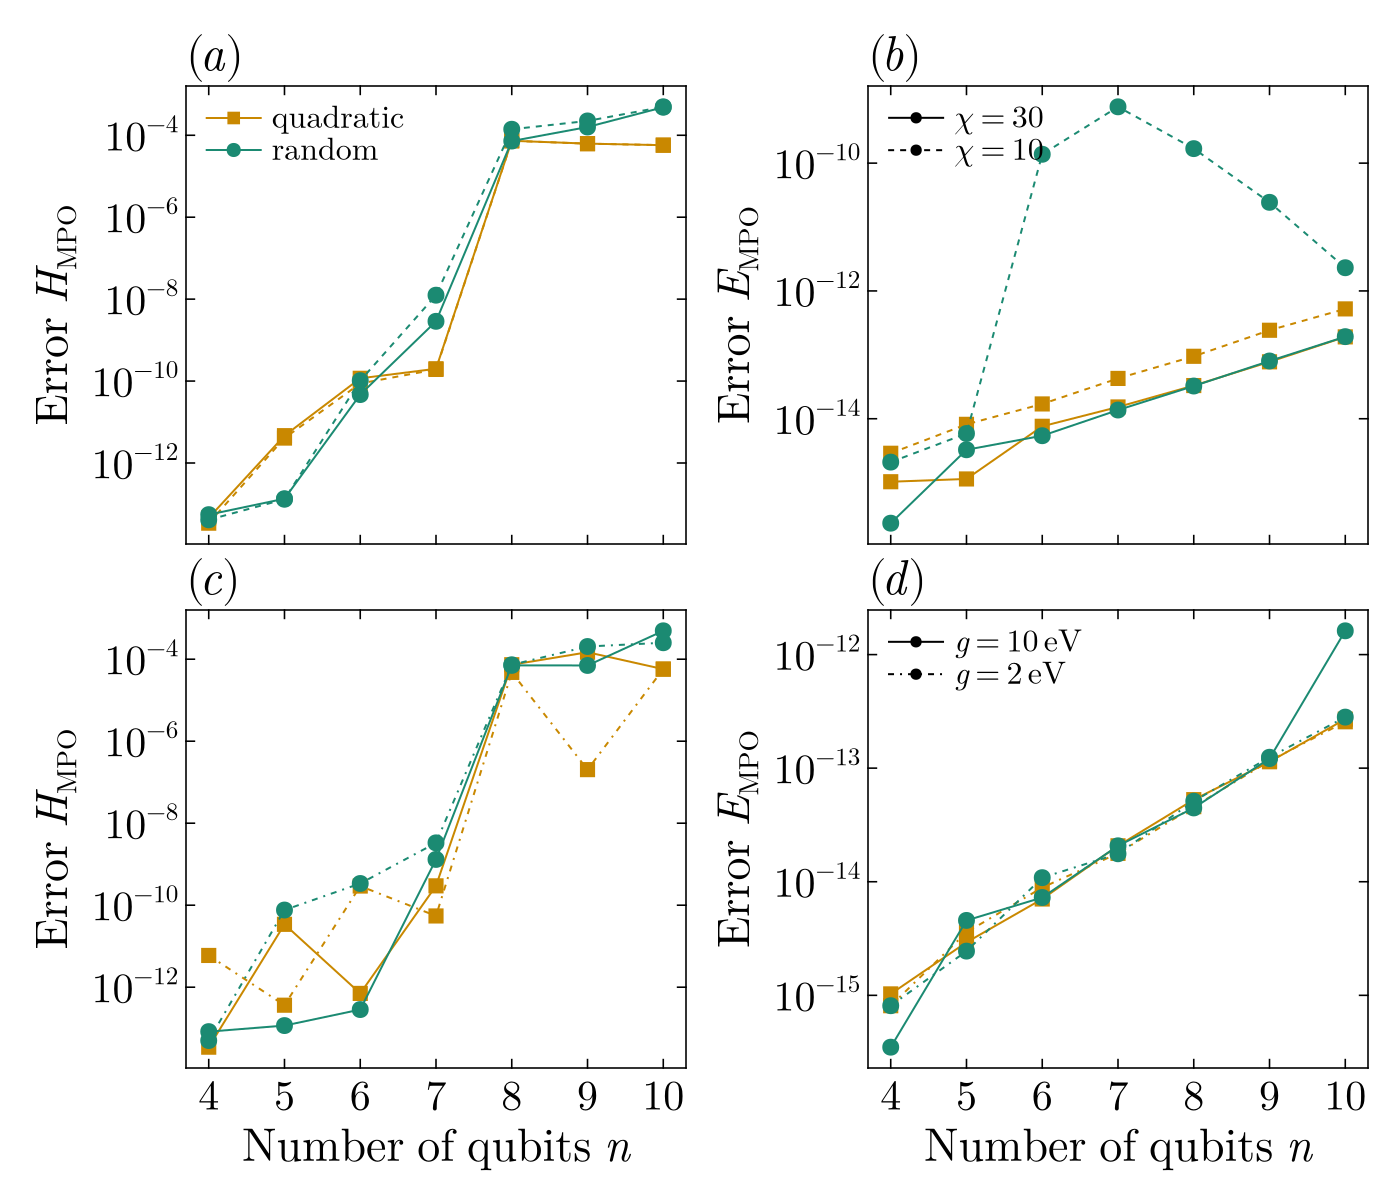

In [5]:
CairoMakie.set_theme!(Theme(
    fontsize = 11,
    font = "Times New Roman",
    Axis = (
        xgridvisible = false,
        ygridvisible = false,
        xlabelsize = 23,
        ylabelsize = 23,
        titlesize = 24,
        xticklabelsize = 21,
        yticklabelsize = 21,
        spinewidth = 0.8,
        xtickwidth = 0.8,
        ytickwidth = 0.8,
        xticksize = 5,
        yticksize = 5,
        xminorticksize = 2.5,
        yminorticksize = 2.5,
        xminorticksvisible = false,
        yminorticksvisible = false,
        ticklabelfont = "Times New Roman",
        labelfont = "Times New Roman",
        titlefont = "Times New Roman",
        xticklabelpad = 3,
        yticklabelpad = 3,
        xtickalign = 1,
        ytickalign = 1,
        xminortickalign = 1,
        yminortickalign = 1,
        xticksmirrored = true,
        yticksmirrored = true,
    ),
))

N_list = 4:10

D_low   = 10
D_high  = 30
D_fixed = 20
g_low   = 2
g_high  = 10
g_fixed = 5

# "Quadratic" label, but same data-file suffix as before
potentials = Dict(
    "Quadratic" => "harmonic",
    "Random"    => "random_potential"
)

palette = Dict(
    "Quadratic" => RGBf(0.788, 0.533, 0.0),
    "Random"    => RGBf(0.106, 0.541, 0.447),
)

markers = Dict(
    "Quadratic" => :rect,
    "Random"    => :circle,
)

fig = Figure(size = (700, 600), backgroundcolor = :white)

# LaTeX tick labels
xtick_latex = (collect(N_list), [L"%$n" for n in N_list])
log_tickformat(vals) = [L"10^{%$(round(Int, log10(v)))}" for v in vals]

ax1 = Axis(fig[1,1],
    ylabel = L"\mathrm{Error}\; H_{\mathrm{MPO}}",
    yscale = log10,
    xticks = xtick_latex,
    ytickformat = log_tickformat,
    title = L"(a)", titlealign = :left, titlegap = 2,
)

ax2 = Axis(fig[1,2],
    ylabel = L"\mathrm{Error}\; E_{\mathrm{MPO}}",
    yscale = log10,
    xticks = xtick_latex,
    ytickformat = log_tickformat,
    title = L"(b)", titlealign = :left, titlegap = 2,
)

ax3 = Axis(fig[2,1],
    xlabel = L"\mathrm{Number}\;\mathrm{of}\;\mathrm{qubits}\; n",
    ylabel = L"\mathrm{Error}\; H_{\mathrm{MPO}}",
    yscale = log10,
    xticks = xtick_latex,
    ytickformat = log_tickformat,
    title = L"(c)", titlealign = :left, titlegap = 2,
)

ax4 = Axis(fig[2,2],
    xlabel = L"\mathrm{Number}\;\mathrm{of}\;\mathrm{qubits}\; n",
    ylabel = L"\mathrm{Error}\; E_{\mathrm{MPO}}",
    yscale = log10,
    xticks = xtick_latex,
    ytickformat = log_tickformat,
    title = L"(d)", titlealign = :left, titlegap = 2,
)

CairoMakie.linkxaxes!(ax1, ax2, ax3, ax4)
CairoMakie.hidexdecorations!(ax1, ticks = false, minorticks = false)
CairoMakie.hidexdecorations!(ax2, ticks = false, minorticks = false)

# ---- (a), (b): fixed g, chi = 30 (solid) and chi = 10 (dashed) ----
for (label, suffix) in potentials
    c  = palette[label]
    mk = markers[label]

    filename  = "err1_low, err2_low, err1_high, err2_high_D_low$(D_low),D_high$(D_high),g_fixed$(g_fixed)$(suffix).jld2"
    filename2 = "err1_low, err2_low, err1_high, err2_high_D_low$(D_low),D_high$(D_high),g_fixed$(g_fixed)$(suffix) (1).jld2"

    @load filename  errorTN_g
    err1_low, err2_low, err1_high, err2_high = errorTN_g
    @load filename2 errorTN_g
    err1_low2, err2_low2, err1_high2, err2_high2 = errorTN_g

    err1_low  = [err1_low...;  err1_low2...]
    err2_low  = [err2_low...;  err2_low2...]
    err1_high = [err1_high...; err1_high2...]
    err2_high = [err2_high...; err2_high2...]

    for (ax, yh, yl) in [(ax1, err1_high, err1_low), (ax2, err2_high, err2_low)]
        lines!(ax, N_list, yh; color = c, linewidth = 1.0, linestyle = :solid)
        scatter!(ax, N_list, yh; color = c, marker = mk, markersize = 12, strokewidth = 0)
        lines!(ax, N_list, yl; color = c, linewidth = 1.0, linestyle = :dash)
        scatter!(ax, N_list, yl; color = c, marker = mk, markersize = 12, strokewidth = 0)
    end
end

# ---- (c), (d): fixed chi, g = 10 eV (solid) and g = 2 eV (dash-dot) ----
for (label, suffix) in potentials
    c  = palette[label]
    mk = markers[label]

    filename  = "err1_low, err2_low, err1_high, err2_high_D_fixe$(D_fixed),g_low $(g_low),g_high $(g_high)$(suffix).jld2"
    filename2 = "err1_low, err2_low, err1_high, err2_high_D_fixe$(D_fixed),g_low $(g_low),g_high $(g_high)$(suffix) (1).jld2"

    @load filename  errorTN_g
    err1_low, err2_low, err1_high, err2_high = errorTN_g
    @load filename2 errorTN_g
    err1_low2, err2_low2, err1_high2, err2_high2 = errorTN_g

    err1_low  = [err1_low...;  err1_low2...]
    err2_low  = [err2_low...;  err2_low2...]
    err1_high = [err1_high...; err1_high2...]
    err2_high = [err2_high...; err2_high2...]

    for (ax, yh, yl) in [(ax3, err1_high, err1_low), (ax4, err2_high, err2_low)]
        lines!(ax, N_list, yh; color = c, linewidth = 1.0, linestyle = :solid)
        scatter!(ax, N_list, yh; color = c, marker = mk, markersize = 12, strokewidth = 0)
        lines!(ax, N_list, yl; color = c, linewidth = 1.0, linestyle = :dashdot)
        scatter!(ax, N_list, yl; color = c, marker = mk, markersize = 12, strokewidth = 0)
    end
end

# ---------------- Legends ----------------
leg_style = (framevisible = false, labelsize = 16, patchsize = (28, 10),
             rowgap = 0, padding = (4, 4, 2, 2))

# Potentials (colour + marker), in panel (a)
pot_order  = ["Quadratic", "Random"]
pot_elems  = [[LineElement(color = palette[l], linewidth = 1.0),
               MarkerElement(color = palette[l], marker = markers[l],
                             markersize = 10, strokewidth = 0)] for l in pot_order]
pot_labels = [L"\mathrm{quadratic}", L"\mathrm{random}"]
axislegend(ax1, pot_elems, pot_labels; position = :lt, leg_style...)

# Bond dimensions (line style), in panel (b)
chi_elems = [[LineElement(color = :black, linestyle = :solid, linewidth = 1.0),
              MarkerElement(color = :black, marker = :circle, markersize = 8)],
             [LineElement(color = :black, linestyle = :dash, linewidth = 1.0),
              MarkerElement(color = :black, marker = :circle, markersize = 8)]]
axislegend(ax2, chi_elems, [L"\chi = 30", L"\chi = 10"]; position = :lt, leg_style...)

# Potential strengths (line style), in panel (d)
g_elems = [[LineElement(color = :black, linestyle = :solid, linewidth = 1.0),
            MarkerElement(color = :black, marker = :circle, markersize = 8)],
           [LineElement(color = :black, linestyle = :dashdot, linewidth = 1.0),
            MarkerElement(color = :black, marker = :circle, markersize = 8)]]
axislegend(ax4, g_elems, [L"g = 10\,\mathrm{eV}", L"g = 2\,\mathrm{eV}"];
           position = :lt, leg_style...)

CairoMakie.colgap!(fig.layout, 14)
CairoMakie.rowgap!(fig.layout, 6)

save("error_analysis_PRL2.pdf", fig)
fig